# Notebook 3 - Real-world wireless tower application

This notebook follows the same experiment structure as `02_evaluate_results.ipynb`:

1. Materialize the geographic application data.
2. Run `real_world_application.json` as a scalable experiment.
3. Run `real_world_application_small_exact.json` with `exact=True`.
4. Aggregate `summary.csv` files and create per-experiment plots.

For exact cases, `accuracy = optimum / selected cardinality`. `quality_vs_reference = reference / selected cardinality`, including best-known references.

In [38]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))

import importlib
import min_cover_set.benchmark as benchmark_module
benchmark_module = importlib.reload(benchmark_module)
run_experiments = benchmark_module.run_experiments

from data_generator import generate_geographic_instance, instance_to_dict

EXPERIMENTS_DIR = REPO_ROOT / "experiments"
DATA_DIR = REPO_ROOT / "data" / "real_world_application"
RESULTS_DIR = REPO_ROOT / "results" / "real_world_application"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SOLVER_SEEDS = tuple(range(20))
BENCHMARK_OPTIONS = {"seeds": SOLVER_SEEDS, "restarts": 30, "rcl_size": 3, "repeats": 3, "overwrite": True}
REQUESTED_EXPERIMENTS = [
    ("real_world_application.json", False),
    ("real_world_application_small_exact.json", True),
]

In [39]:
def missing_manifest_inputs(manifest_path):
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    missing = []
    for specification in manifest["instances"]:
        if "path" in specification:
            input_path = (manifest_path.parent / specification["path"]).resolve()
            if not input_path.is_file():
                missing.append((specification["name"], input_path))
    return missing

# Materialize every generated geographic application instance.
manifest = json.loads((EXPERIMENTS_DIR / "real_world_application.json").read_text(encoding="utf-8"))
for specification in manifest["instances"]:
    generation = specification["generate"]
    instance = generate_geographic_instance(
        grid_width=generation["grid_width"],
        grid_height=generation["grid_height"],
        num_tower_candidates=generation["num_tower_candidates"],
        coverage_radius=generation["coverage_radius"],
        seed=generation["seed"],
    )
    payload = instance_to_dict(instance)
    payload["metadata"] = {
        "application": "wireless_towers",
        "name": specification["name"],
        "family": specification["family"],
        **{key: value for key, value in generation.items() if key != "_generator"},
    }
    (DATA_DIR / f"{specification['name']}.json").write_text(
        json.dumps(payload, indent=2) + "\n", encoding="utf-8"
    )

EXPERIMENTS = []
for manifest_name, exact in REQUESTED_EXPERIMENTS:
    manifest_path = EXPERIMENTS_DIR / manifest_name
    if not manifest_path.is_file():
        print(f"SKIP {manifest_name}: manifest not found")
        continue
    missing = missing_manifest_inputs(manifest_path)
    if missing:
        print(f"SKIP {manifest_name}: {len(missing)} input file(s) are missing")
        continue
    EXPERIMENTS.append((manifest_name, exact))

print("Experiments selected:", ", ".join(name for name, _ in EXPERIMENTS))

Experiments selected: real_world_application.json, real_world_application_small_exact.json


In [40]:
run_metadata = []
for manifest_name, exact in EXPERIMENTS:
    manifest_path = EXPERIMENTS_DIR / manifest_name
    output_dir = RESULTS_DIR / manifest_path.stem
    print(f"Running {manifest_name} ({'exact' if exact else 'scalable'})...")
    metadata = run_experiments(manifest_path, output_dir, exact=exact, **BENCHMARK_OPTIONS)
    run_metadata.append({
        "experiment": manifest_path.stem,
        "exact": exact,
        "instances": metadata["instances"],
        "runs": metadata["measured_runs"],
        "output": str(output_dir.relative_to(REPO_ROOT)),
    })

run_metadata_df = pd.DataFrame(run_metadata)
display(run_metadata_df)
print("Benchmark files per experiment: runs.csv, summary.csv, solutions.jsonl, environment.json")

Running real_world_application.json (scalable)...
Running real_world_application_small_exact.json (exact)...


,experiment,exact,instances,runs,output
0,real_world_application,False,27,621,results/real_world_application/real_world_appl...
1,real_world_application_small_exact,True,9,315,results/real_world_application/real_world_appl...


Benchmark files per experiment: runs.csv, summary.csv, solutions.jsonl, environment.json


In [41]:
summary_frames = []
required_columns = {"algorithm", "n", "time_ms_mean", "cardinality_mean", "accuracy_mean", "quality_vs_reference_mean"}
for item in run_metadata:
    summary_path = REPO_ROOT / item["output"] / "summary.csv"
    frame = pd.read_csv(summary_path)
    missing_columns = required_columns - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{summary_path} is missing columns: {sorted(missing_columns)}")
    frame["experiment"] = item["experiment"]
    summary_frames.append(frame)

summary_df = pd.concat(summary_frames, ignore_index=True)
summary_df.to_csv(RESULTS_DIR / "all_summaries.csv", index=False)
display(summary_df[["experiment", "instance", "algorithm", "n", "reference_kind", "cardinality_mean", "accuracy_mean", "quality_vs_reference_mean", "time_ms_mean"]].head())

,experiment,instance,algorithm,n,reference_kind,cardinality_mean,accuracy_mean,quality_vs_reference_mean,time_ms_mean
0,real_world_application,app_n10_m6_r1_g11,randomized_greedy,10,unknown,3.0,NaN,NaN,0.590548
1,real_world_application,app_n10_m6_r1_g11,greedy,10,unknown,3.0,NaN,NaN,0.007403
2,real_world_application,app_n10_m6_r1_g22,randomized_greedy,10,unknown,3.0,NaN,NaN,0.599352
3,real_world_application,app_n10_m6_r1_g22,greedy,10,unknown,3.0,NaN,NaN,0.008153
4,real_world_application,app_n10_m6_r1_g33,randomized_greedy,10,unknown,4.0,NaN,NaN,0.521229


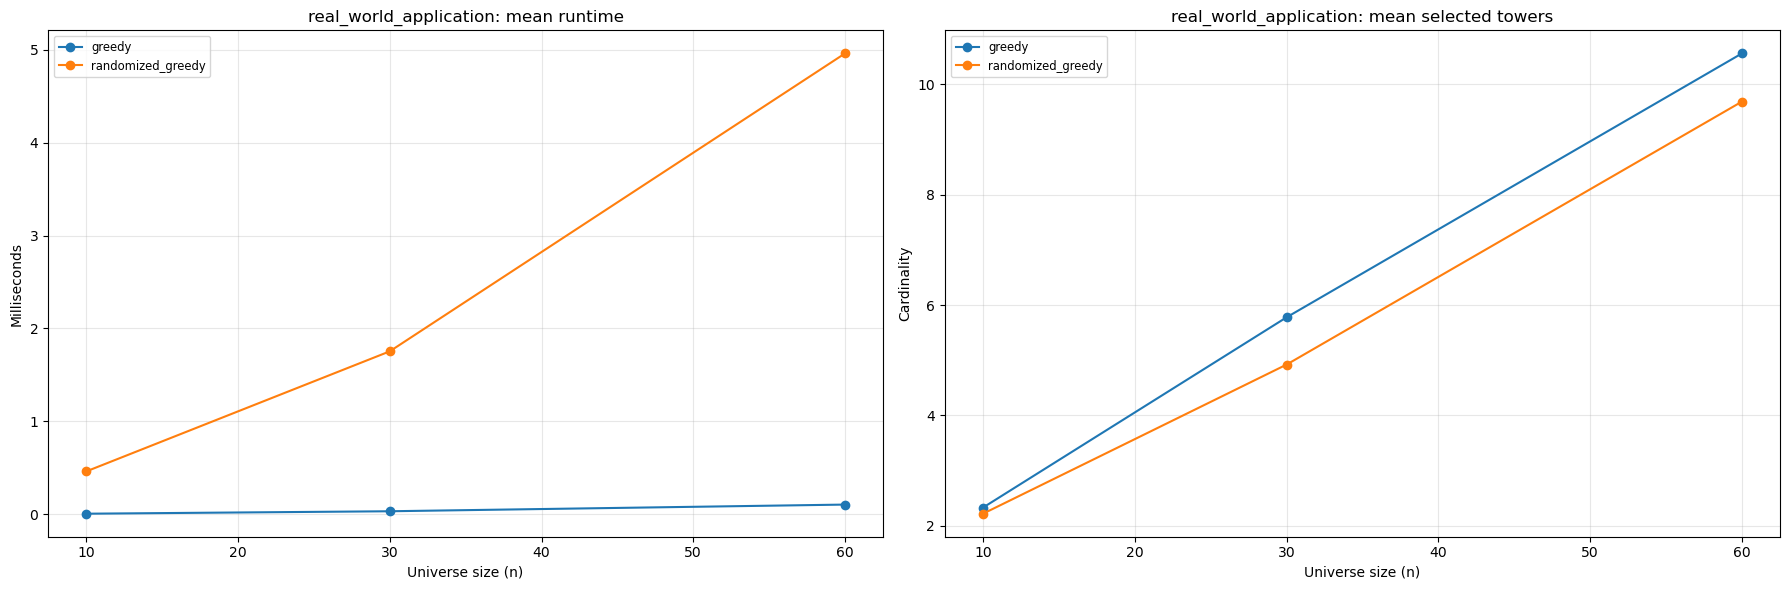

Saved results/real_world_application/real_world_application/runtime_cardinality.png


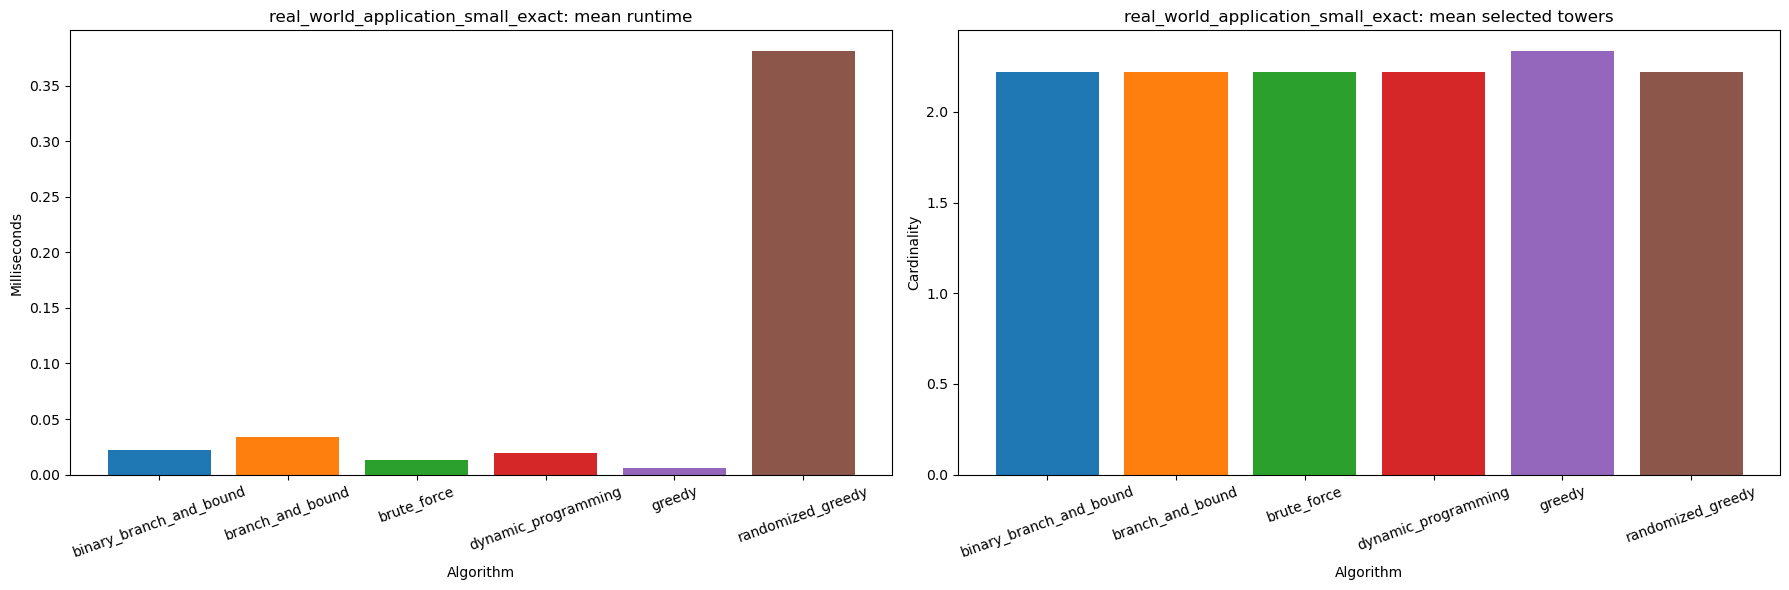

Saved results/real_world_application/real_world_application_small_exact/runtime_cardinality_bar.png


In [42]:
# Runtime and cardinality plots, separate for each application experiment.
experiment = "real_world_application"
experiment_df = summary_df[summary_df["experiment"] == experiment]
plot_summary = (
    experiment_df.groupby(["algorithm", "n"], as_index=False)
    .agg(time_ms_mean=("time_ms_mean", "mean"), cardinality_mean=("cardinality_mean", "mean"))
    .sort_values("n")
)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for algorithm, group in plot_summary.groupby("algorithm"):
    axes[0].plot(group["n"], group["time_ms_mean"], marker="o", label=algorithm)
    axes[1].plot(group["n"], group["cardinality_mean"], marker="o", label=algorithm)
axes[0].set(title=f"{experiment}: mean runtime", xlabel="Universe size (n)", ylabel="Milliseconds")
axes[1].set(title=f"{experiment}: mean selected towers", xlabel="Universe size (n)", ylabel="Cardinality")
for axis in axes:
    axis.grid(True, alpha=0.3)
    axis.legend(fontsize="small")
fig.tight_layout()
plot_path = RESULTS_DIR / experiment / "runtime_cardinality.png"
fig.savefig(plot_path, dpi=150)
plt.show()
plt.close(fig)
print(f"Saved {plot_path.relative_to(REPO_ROOT)}")


# bar plot for runtime and cardinality, especially for the small exact experiment with universize = 10 and multiple algorithms
# x-axis: algorithm, y-axis: mean runtime and mean cardinality, two subplots
experiment = "real_world_application_small_exact"
experiment_df = summary_df[summary_df["experiment"] == experiment]
plot_summary = (
    experiment_df.groupby(["algorithm", "n"], as_index=False)
    .agg(time_ms_mean=("time_ms_mean", "mean"), cardinality_mean=("cardinality_mean", "mean"))
    .sort_values("n")
)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for algorithm, group in plot_summary.groupby("algorithm"):
    # algorithms 45 do
    axes[0].bar(group["algorithm"], group["time_ms_mean"], label=algorithm)
    axes[1].bar(group["algorithm"], group["cardinality_mean"], label=algorithm)
axes[0].set(title=f"{experiment}: mean runtime", xlabel="Algorithm", ylabel="Milliseconds")
axes[1].set(title=f"{experiment}: mean selected towers", xlabel="Algorithm", ylabel="Cardinality")
axes[0].xaxis.set_tick_params(rotation=20)
axes[1].xaxis.set_tick_params(rotation=20)
fig.tight_layout()
plot_path = RESULTS_DIR / experiment / "runtime_cardinality_bar.png"
fig.savefig(plot_path, dpi=150)
plt.show()
plt.close(fig)
print(f"Saved {plot_path.relative_to(REPO_ROOT)}")


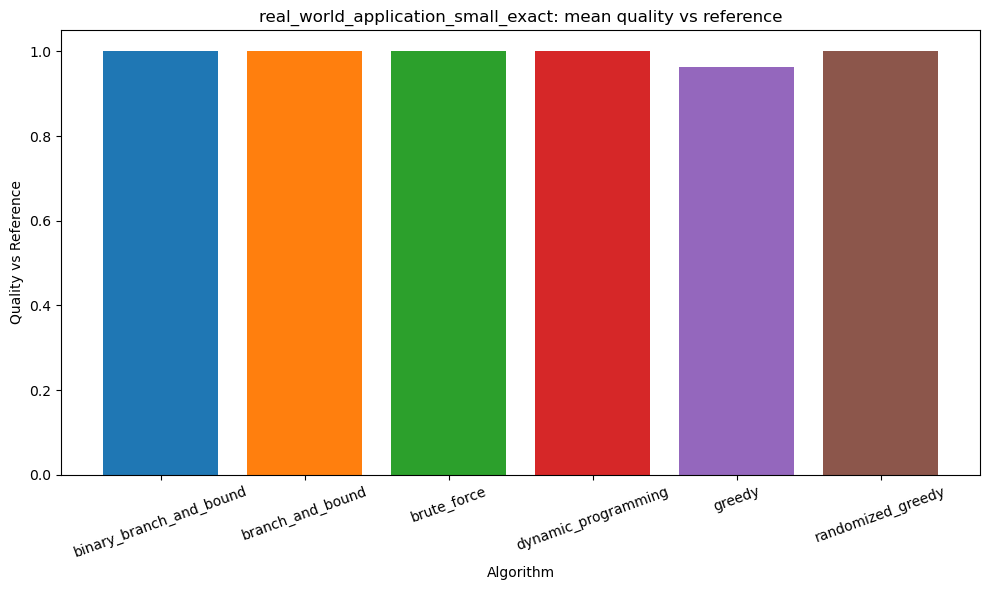

Saved results/real_world_application/real_world_application_small_exact/quality_vs_reference_bar.png


In [43]:
# Quality versus the declared reference, separate for small exact application experiment.
# one n = 10, multiple algorithms, bar plot
experiment = "real_world_application_small_exact"
experiment_df = summary_df[summary_df["experiment"] == experiment]
plot_summary = (
    experiment_df.groupby(["algorithm", "n"], as_index=False)
    .agg(quality_vs_reference_mean=("quality_vs_reference_mean", "mean"))
    .sort_values("n")
)
fig, ax = plt.subplots(figsize=(10, 6))
for algorithm, group in plot_summary.groupby("algorithm"):
    ax.bar(group["algorithm"], group["quality_vs_reference_mean"], label=algorithm)
ax.set(title=f"{experiment}: mean quality vs reference", xlabel="Algorithm", ylabel="Quality vs Reference")
ax.xaxis.set_tick_params(rotation=20)
fig.tight_layout()
plot_path = RESULTS_DIR / experiment / "quality_vs_reference_bar.png"
fig.savefig(plot_path, dpi=150)
plt.show()
plt.close(fig)
print(f"Saved {plot_path.relative_to(REPO_ROOT)}")

In [44]:
# Mean total summary grouped by universe size and algorithm.
mean_total_summary = (
    summary_df.groupby(["n", "algorithm"], as_index=False)
    .agg(
        experiments=("experiment", "nunique"),
        instances=("instance", "nunique"),
        time_ms_mean=("time_ms_mean", "mean"),
        cardinality_mean=("cardinality_mean", "mean"),
        cardinality_sd_mean=("cardinality_sd", "mean"),
        accuracy_mean=("accuracy_mean", "mean"),
        quality_vs_reference_mean=("quality_vs_reference_mean", "mean"),
    )
    .sort_values(["n", "algorithm"])
)
mean_total_summary.to_csv(RESULTS_DIR / "mean_total_summary_by_universe_size.csv", index=False)
display(mean_total_summary)
print(f"Saved {RESULTS_DIR / 'mean_total_summary_by_universe_size.csv'}")

,n,algorithm,experiments,instances,time_ms_mean,cardinality_mean,cardinality_sd_mean,accuracy_mean,quality_vs_reference_mean
0,10,binary_branch_and_bound,1,9,0.022111,2.222222,0.000000,1.000000,1.000000
1,10,branch_and_bound,1,9,0.033860,2.222222,0.000000,1.000000,1.000000
2,10,brute_force,1,9,0.013233,2.222222,0.000000,1.000000,1.000000
3,10,dynamic_programming,1,9,0.019776,2.222222,0.000000,1.000000,1.000000
4,10,greedy,2,9,0.006356,2.333333,0.000000,0.962963,0.962963
5,10,randomized_greedy,2,9,0.420952,2.222222,0.000000,1.000000,1.000000
6,30,greedy,1,9,0.033009,5.777778,0.000000,NaN,NaN
7,30,randomized_greedy,1,9,1.753666,4.922222,0.199866,NaN,NaN
8,60,greedy,1,9,0.104891,10.555556,0.000000,NaN,NaN
9,60,randomized_greedy,1,9,4.960578,9.683333,0.220253,NaN,NaN


Saved /Users/vnpq/_MLDM/Advanced Algo & programming/MinimumCoverSet/results/real_world_application/mean_total_summary_by_universe_size.csv
